# 04b · Weather forecast vs actual: error analysis and simulation
Chain: weather forecast error → wind/solar forecast error → residual-load error → price error. Only the archived D-1 forecast (Open-Meteo Previous Runs API, day-1 run) is used as a model feature.

In [1]:
import sys, json, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Image, display
R = ROOT / "reports"
plt.rcParams.update({"figure.figsize": (11, 4.2), "axes.grid": True, "grid.alpha": .3,
                     "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})
ACC, BLUE, TEAL, RED, GREY = "#E08E0B", "#3F6FD8", "#1E9E92", "#D64545", "#7A8194"
pd.set_option("display.float_format", "{:,.2f}".format)


## 1. Weather forecast (D-1) vs observed

In [2]:
we = pd.read_csv(R / "weather_fc_error.csv"); display(we[we.season == "all"].round(2))
display(we.pivot_table(index=["variable", "point"], columns="season", values="MAE").round(2))

,variable,point,season,bias,MAE,RMSE,error_sd,n
0,temp,sofia,all,0.41,1.27,1.71,1.66,23706
5,wind100,sofia,all,0.31,1.33,1.76,1.73,23706
10,rad,sofia,all,-9.81,23.68,53.38,52.47,23706
15,cloud,sofia,all,8.42,20.07,31.09,29.93,23706
20,temp,dobrich,all,-0.06,0.90,1.17,1.17,23706
25,wind100,dobrich,all,0.04,1.07,1.40,1.40,23706
30,rad,dobrich,all,-6.73,23.43,55.10,54.69,23706
35,cloud,dobrich,all,6.43,19.79,31.85,31.20,23706
40,temp,stara_zagora,all,1.11,1.41,1.85,1.48,23706
45,wind100,stara_zagora,all,-0.61,1.21,1.60,1.48,23706


season                  all  autumn  spring  summer  winter
variable point                                             
cloud    dobrich      19.79   20.07   20.14   21.21   16.93
         sofia        20.07   19.28   19.80   21.84   18.94
         stara_zagora 20.12   19.18   21.07   21.96   17.32
rad      dobrich      23.43   18.42   30.82   27.12   13.96
         sofia        23.68   19.86   29.35   26.77   16.01
         stara_zagora 22.47   17.46   28.80   26.07   14.65
temp     dobrich       0.90    0.83    0.88    1.01    0.86
         sofia         1.27    1.22    1.36    1.03    1.56
         stara_zagora  1.41    1.44    1.50    1.07    1.73
wind100  dobrich       1.07    1.02    1.08    1.08    1.08
         sofia         1.33    1.25    1.45    1.20    1.45
         stara_zagora  1.21    1.17    1.23    1.19    1.27

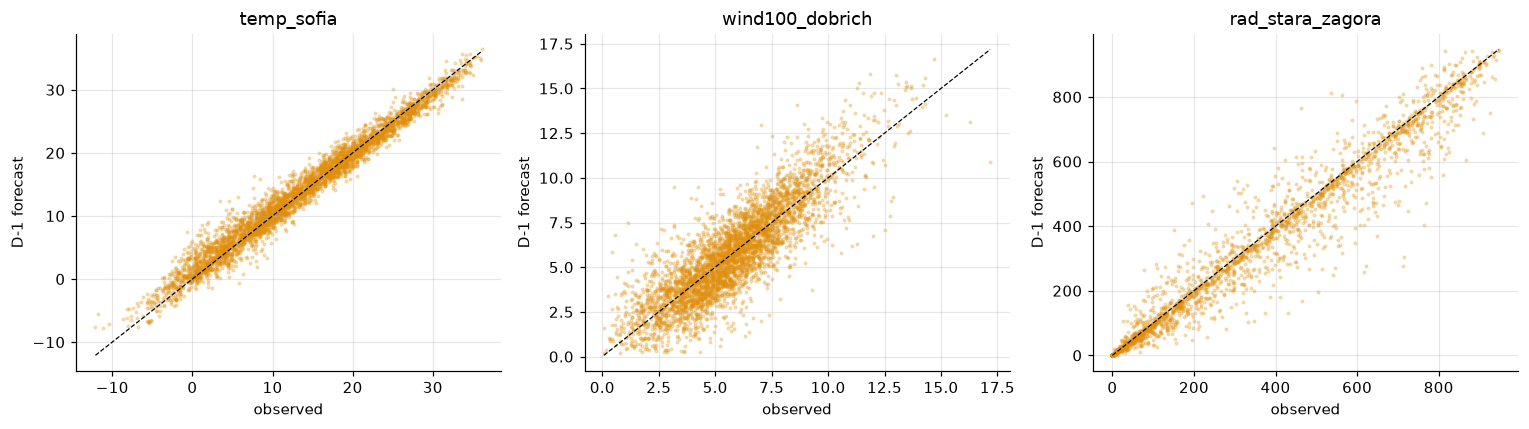

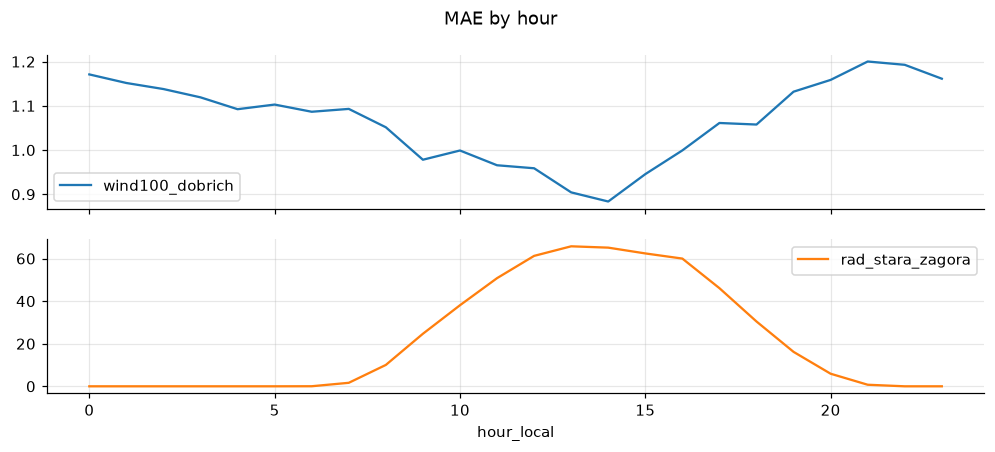

In [3]:
s = pd.read_csv(R / "weather_fc_vs_actual_sample.csv")
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
for a, v in zip(ax, ["temp_sofia", "wind100_dobrich", "rad_stara_zagora"]):
    a.scatter(s["wact_" + v], s["wfc_" + v], s=3, alpha=.25, color=ACC); lim = [s["wact_" + v].min(), s["wact_" + v].max()]
    a.plot(lim, lim, "k--", lw=.8); a.set_xlabel("observed"); a.set_ylabel("D-1 forecast"); a.set_title(v)
plt.tight_layout(); plt.show()
pd.read_csv(R / "weather_fc_error_by_hour.csv", index_col=0)[["wind100_dobrich", "rad_stara_zagora"]].plot(subplots=True, figsize=(11, 4), title="MAE by hour")
plt.show()

## 2. ENTSO-E wind/solar forecast vs actual generation

,0
wind_mae_mw,65.58
wind_bias_mw,30.97
wind_mae_pct_of_mean,42.52
solar_mae_mw,240.88
solar_bias_mw,44.41
solar_mae_pct_of_mean,37.38
solar_err_r2_vs_weather_err,0.00
wind_err_r2_vs_weather_err,0.02


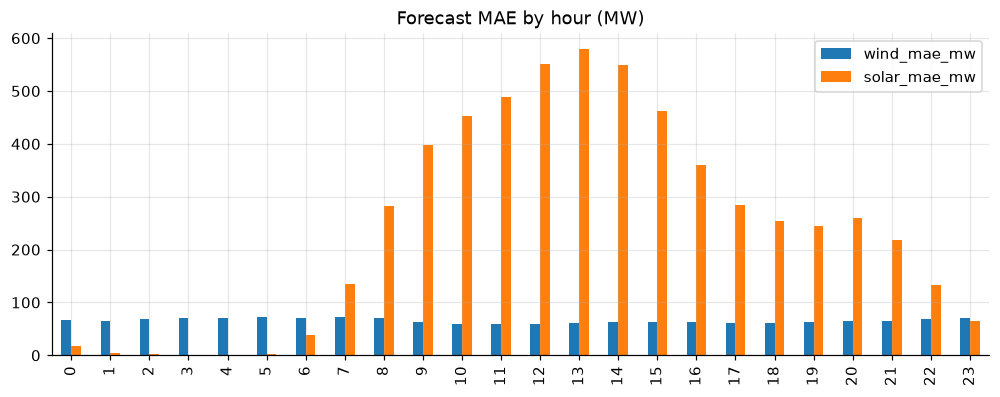

Solar error by hour is concentrated in daylight hours: 13 :00 peak


In [4]:
rs = pd.read_csv(R / "res_forecast_error_summary.csv"); display(rs.T.round(3))
rt = pd.read_csv(R / "res_forecast_error_by_hour_month.csv", index_col=0)
rt[[c for c in rt if not c.startswith("m_")]].plot.bar(figsize=(11, 3.8), title="Forecast MAE by hour (MW)"); plt.show()
print("Solar error by hour is concentrated in daylight hours:", (rt.solar_mae_mw.idxmax()), ":00 peak")

## 3. From residual-load forecast error to price error

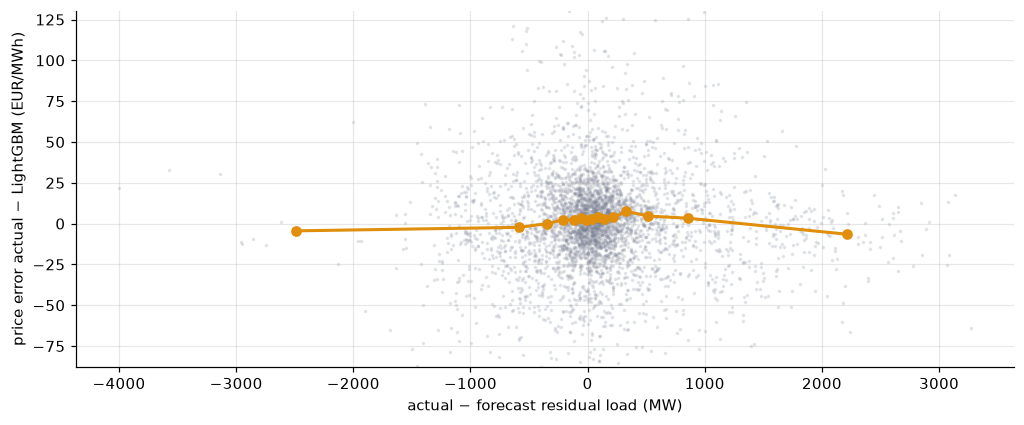

Takeaway: slope = -0.01 EUR/MWh per 100 MW of residual-load miss, i.e. about zero.


,delivery_day,mean_abs_res_err_mw,mean_price_err,mae_price
0,2026-08-21,"1,650.40",14.60,15.80
1,2026-06-07,"1,169.70",-23.80,23.80
2,2026-04-26,"1,164.00",-18.10,21.50
3,2026-06-14,"1,153.30",-0.80,12.20
4,2026-03-31,"1,135.90",9.60,18.10
5,2026-05-01,"1,129.60",-23.50,26.50
6,2026-05-24,"1,120.50",7.90,18.20
7,2026-05-17,"1,087.50",17.80,19.40
8,2026-05-03,"1,080.50",10.20,11.10
9,2026-06-13,"1,034.70",-29.40,31.10


In [5]:
l = pd.read_csv(R / "res_error_vs_price_error.csv")
b = pd.qcut(l.res_load_err_mw, 15); g = l.groupby(b, observed=True).price_err.mean()
plt.scatter(l.res_load_err_mw[::5], l.price_err[::5], s=2, alpha=.15, color=GREY)
plt.plot([i.mid for i in g.index], g.values, "o-", color=ACC, lw=2); plt.ylim(l.price_err.quantile(.01), l.price_err.quantile(.99))
plt.xlabel("actual − forecast residual load (MW)"); plt.ylabel("price error actual − LightGBM (EUR/MWh)"); plt.show()
slope = np.polyfit(l.res_load_err_mw, l.price_err, 1)[0]
print(f"Takeaway: slope = {100 * slope:+.2f} EUR/MWh per 100 MW of residual-load miss, i.e. about zero.")
display(pd.read_csv(R / "worst_res_forecast_days.csv").round(1))

Why is there no relationship? The **day-ahead price is cleared on D-1 forecasts**, so a miss in the realised residual load cannot change it; it moves intraday and imbalance prices instead. The price-forecast error comes from what the market knew on D-1 and our model did not (fuel prices, outages, cross-border capacity).

## 4. Oracle vs realistic vs no weather (key comparison)
Same LightGBM settings and months; only the weather inputs differ. Months where the D-1 archive is incomplete are excluded.

In [6]:
ex = pd.read_csv(R / "weather_experiment.csv").set_index("setup").MAE; display(ex.round(3))
print(f"Cost of weather-forecast uncertainty (realistic − oracle): {ex.realistic - ex.oracle:+.3f} EUR/MWh")
print(f"Value of weather information (no weather − realistic): {ex.no_weather - ex.realistic:+.3f} EUR/MWh")

setup
oracle       23.69
realistic    23.62
no_weather   24.17
Name: MAE, dtype: float64

Cost of weather-forecast uncertainty (realistic − oracle): -0.073 EUR/MWh
Value of weather information (no weather − realistic): +0.555 EUR/MWh


## 5. Noise-injection simulation
Oracle weather + Gaussian noise with the measured forecast-error SD × scale, 3 seeds per level, last 6 months.

,noise_scale,mean,std,count
0,0.00,24.48,0.00,1
1,0.50,24.52,0.15,3
2,1.00,24.51,0.16,3
3,2.00,24.57,0.17,3


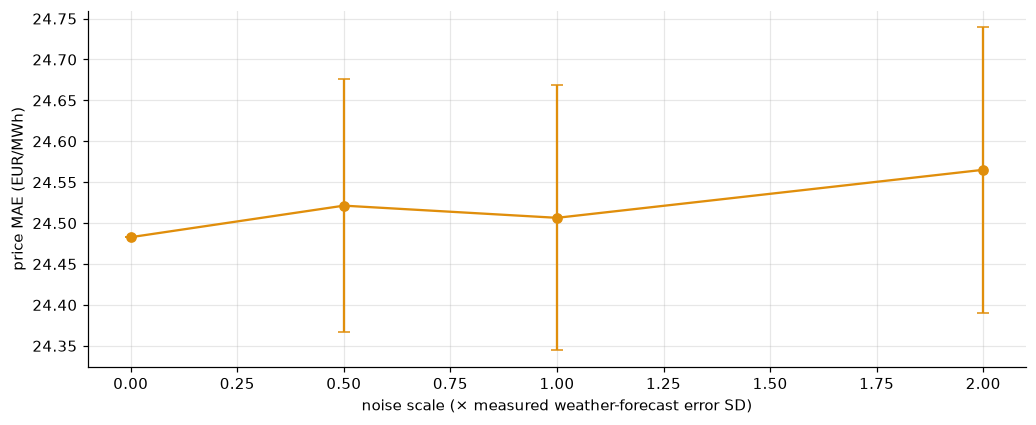

In [7]:
nz = pd.read_csv(R / "weather_noise_injection.csv"); display(nz.round(3))
plt.errorbar(nz.noise_scale, nz["mean"], yerr=nz["std"], marker="o", color=ACC, capsize=4)
plt.xlabel("noise scale (× measured weather-forecast error SD)"); plt.ylabel("price MAE (EUR/MWh)"); plt.show()

## 6. Business takeaway

In [8]:
display(pd.read_csv(R / "battery_weather_scenarios.csv", index_col=0)[["eur_per_mw_year", "pct_of_perfect"]].round(1))

,eur_per_mw_year,pct_of_perfect
strategy,,
perfect_foresight,"105,534.50",100.00
oracle_weather,"84,376.40",80.00
realistic_weather,"84,517.40",80.10
no_weather,"85,021.60",80.60
noisy_0.5x,"84,461.80",80.00
noisy_1.0x,"85,179.90",80.70
noisy_2.0x,"84,636.20",80.20


**What the data says.** Point weather forecasts add a little accuracy (no-weather vs realistic), but the oracle barely beats the realistic D-1 forecast, and injecting up to 2× the measured weather error leaves price MAE almost unchanged. Battery revenue is also nearly identical across the weather scenarios. The reasons: (1) the ENTSO-E load/wind/solar forecasts already carry the weather signal; (2) the day-ahead price itself is set on D-1 forecasts, so the realised weather cannot move it; (3) the model is dominated by price lags and neighbour prices. The ENTSO-E solar forecast error is large and growing but almost uncorrelated with point-weather error, which points to capacity growth and curtailment rather than weather.

**So what for a trader:** weather-forecast risk is mainly an intraday/balancing exposure. Hedge more on high-solar and volatile-wind days, widen the risk band in the midday solar hours, and re-optimise after intraday weather updates.